# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [2]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN, KMeans
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from utils import plot_complex_fit, plot_decision_boundary




# Any other imports you need


## Binary classification


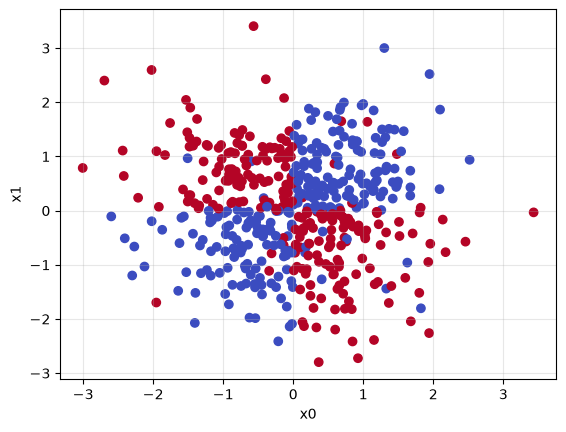

In [3]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
    ###       FULL BATCH VS. MINI-BATCH       ###

# Data

x_train = torch.tensor(train[["x0", "x1"]].values, dtype=torch.float32)
y_train = torch.tensor(train[["y"]].values, dtype=torch.float32)
x_test = torch.tensor(test[["x0", "x1"]].values, dtype=torch.float32)
y_test = torch.tensor(test[["y"]].values, dtype=torch.float32)





In [5]:
# Funksjoner

def create_model(activation = nn.ReLU, hidden_size = 8):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(2, hidden_size),
        activation(),
        nn.Linear(hidden_size, 1),
        )


def create_deep_model(activation = nn.ReLU, hidden_size = 64):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(2, hidden_size),
        activation(),
        nn.Linear(hidden_size, hidden_size),
        activation(),
        nn.Linear(hidden_size, 1),
    )



def accuracy(model, x, y):
    with torch.no_grad():
        predictions = (torch.sigmoid(model(x)) > 0.5).float()
        return (predictions == y).float().mean().item()


def train_full_batch(model, lr, epochs):
    optimizer = torch.optim.SGD(model.parameters(), lr)
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

def train_mini_batch(model, lr, epochs, batch_size=32):
    optimizer = torch.optim.SGD(model.parameters(), lr)
    loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
    losses = []
    for epoch in range(epochs):
        batch_losses = []
        for x_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x_batch), y_batch)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        losses.append(sum(batch_losses) / len(batch_losses))
    return losses



#  loss function, learning rate, epochs and loss-list

loss_fn = nn.BCEWithLogitsLoss()
lr = 0.1
epochs = 1000

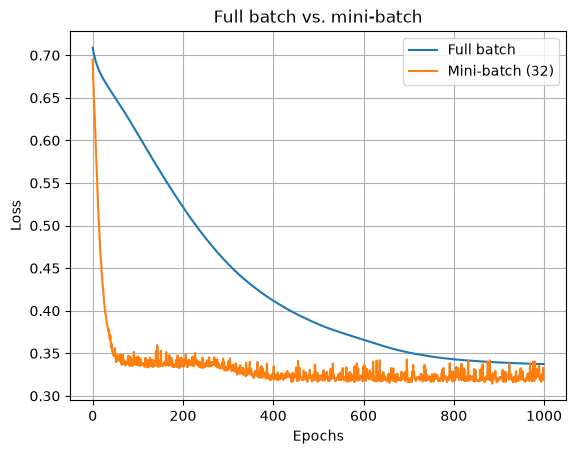

Full batch  - train: 0.9319999814033508  test: 0.9139999747276306
Mini-batch  - train: 0.9200000166893005  test: 0.9039999842643738


In [6]:
model_full = create_model()
losses_full = train_full_batch(model_full, lr, epochs)

model_mini = create_model()
losses_mini = train_mini_batch(model_mini, lr, epochs)

plt.plot(losses_full, label="Full batch")
plt.plot(losses_mini, label="Mini-batch (32)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Full batch vs. mini-batch")
plt.legend()
plt.grid()
plt.show()

print("Full batch  - train:", accuracy(model_full, x_train, y_train), " test:", accuracy(model_full, x_test, y_test))
print("Mini-batch  - train:", accuracy(model_mini, x_train, y_train), " test:", accuracy(model_mini, x_test, y_test))

lr = 1: test accuracy 0.908
lr = 0.1: test accuracy 0.914
lr = 0.01: test accuracy 0.664


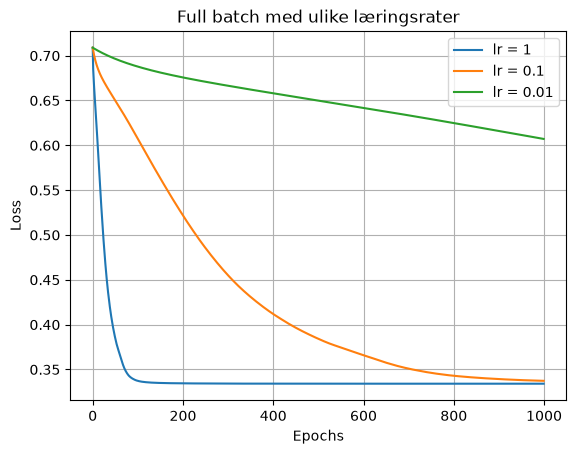

In [7]:
# Metode nr 2: LR

# Metode 2: læringsrate
for lr_value in [1, 0.1, 0.01]:
    model = create_model()
    losses = train_full_batch(model, lr_value, epochs)
    plt.plot(losses, label=f"lr = {lr_value}")
    print(f"lr = {lr_value}: test accuracy {accuracy(model, x_test, y_test):.3f}")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Full batch med ulike læringsrater")
plt.legend()
plt.grid()
plt.show()


ReLU: test accuracy 0.914
Tanh: test accuracy 0.890


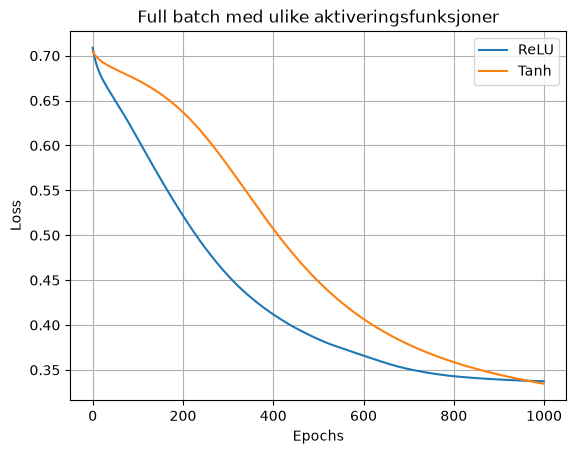

In [8]:
#   METODE NR. 3 - AKTIVERINGSFUNKSJONER

for name, act in [("ReLU", nn.ReLU), ("Tanh", nn.Tanh)]:
    model = create_model(act)
    losses = train_full_batch(model, lr, epochs)
    plt.plot(losses, label=name)
    print(f"{name}: test accuracy {accuracy(model, x_test, y_test):.3f}")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Full batch med ulike aktiveringsfunksjoner")
plt.legend()
plt.grid()
plt.show()

### ❓ Visualize the network architecture for both classification and regression.


### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values?

## Regression


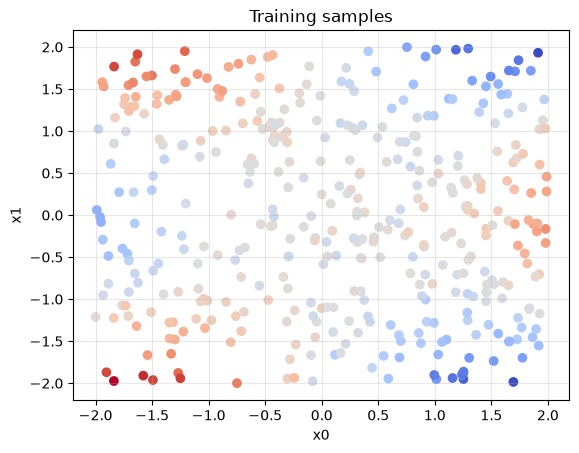

In [9]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

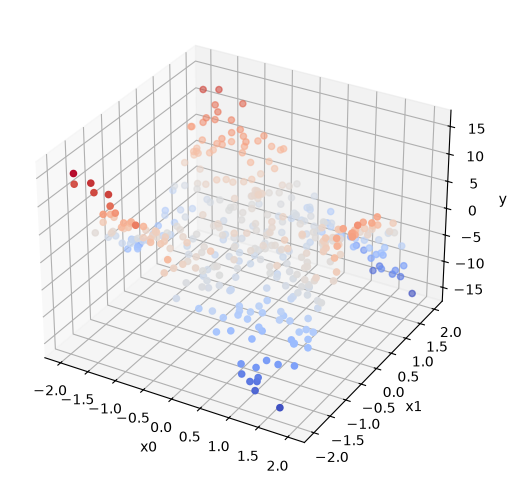

In [10]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

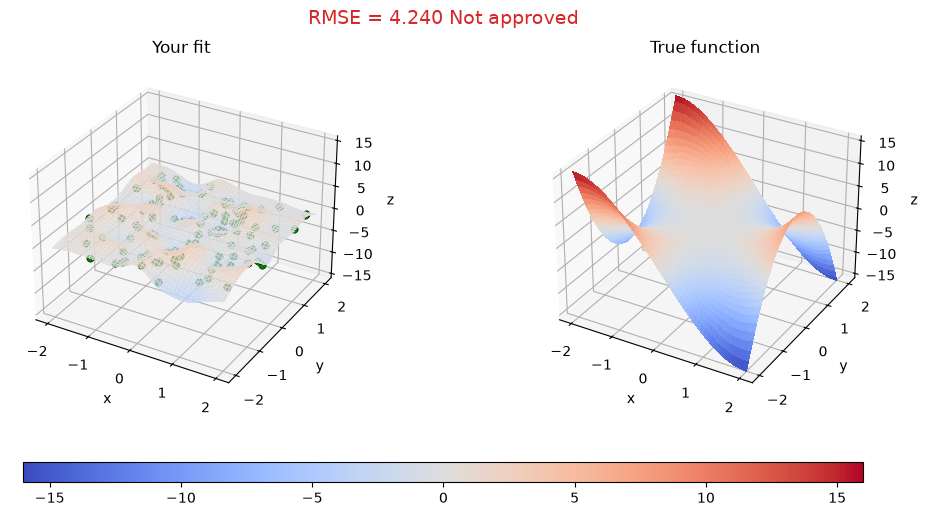

In [11]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))
plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

In [12]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

# REGRESJON: DATA

x_train_reg = torch.tensor(train[["x0", "x1"]].values, dtype=torch.float32)
y_train_reg = torch.tensor(train[["y"]].values, dtype=torch.float32)
x_test_reg = torch.tensor(test[["x0", "x1"]].values, dtype=torch.float32)

# 80 % trening, 20 % validering (testsettet har ingen fasit)
x_tr_reg, x_val_reg, y_tr_reg, y_val_reg = train_test_split(
    x_train_reg, y_train_reg, test_size=0.2, random_state=42
)

loss_fn_reg = nn.MSELoss()





In [13]:

# REGRESJON: FUNKSJONER

def train_reg(model, x_tr, y_tr, x_val, y_val, loss_fn, lr, epochs, weight_decay=0):
    optimizer = torch.optim.Adam(model.parameters(), lr, weight_decay=weight_decay)
    losses = []
    val_losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        predictions = model(x_tr)
        loss = loss_fn(predictions, y_tr)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

        with torch.no_grad():
            val_predictions = model(x_val)
            val_loss = loss_fn(val_predictions, y_val)
            val_losses.append(val_loss.item())

    return losses, val_losses


def plot_test_fit(model, y_mean=0, y_std=1):
    with torch.no_grad():
        test_predictions = model(x_test_reg)

    pred = (test_predictions * y_std) + y_mean
    plot_complex_fit(test_xy, pred.flatten().numpy())
    plt.show()


def plot_train_val(losses, val_losses, title):
    plt.plot(losses, label="Train")
    plt.plot(val_losses, label="Validation")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("MSE (log)")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

def run_with_early_stopping(title, builder, activation, hidden_size, lr, y_tr, y_val,
                            epochs=5000, weight_decay=0, y_mean=0, y_std=1):
    """Tren i full lengde, finn beste epoke, tren på nytt til den epoken."""
    model = builder(activation=activation, hidden_size=hidden_size)
    losses, val_losses = train_reg(model, x_tr_reg, y_tr, x_val_reg, y_val,
                                   loss_fn_reg, lr, epochs, weight_decay)
    best_epoch = val_losses.index(min(val_losses))
    plot_train_val(losses, val_losses, f"{title} (beste epoke: {best_epoch})")

    model_es = builder(activation=activation, hidden_size=hidden_size)
    train_reg(model_es, x_tr_reg, y_tr, x_val_reg, y_val,
              loss_fn_reg, lr, best_epoch + 1, weight_decay)
    plot_test_fit(model_es, y_mean, y_std)
    return model_es, best_epoch

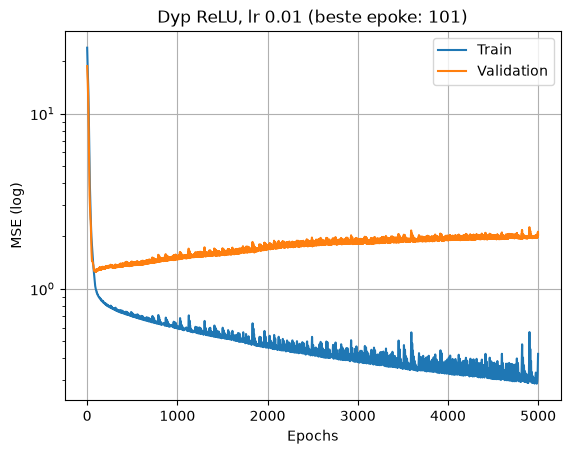

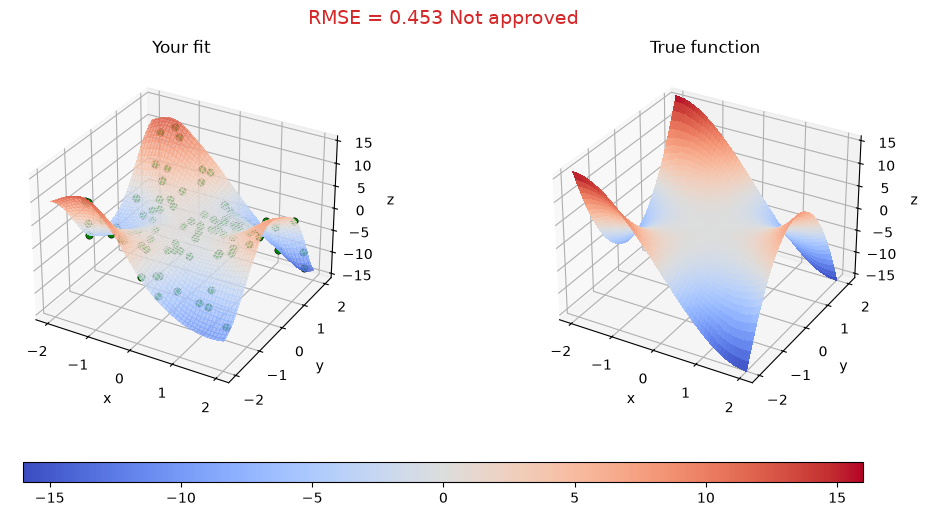

In [14]:

# EKSPERIMENT 1: dyp relu, LR 0.01, early stopping

model_relu, best_relu = run_with_early_stopping(
    "Dyp ReLU, lr 0.01", create_deep_model, nn.ReLU, 64, 0.01, y_tr_reg, y_val_reg)

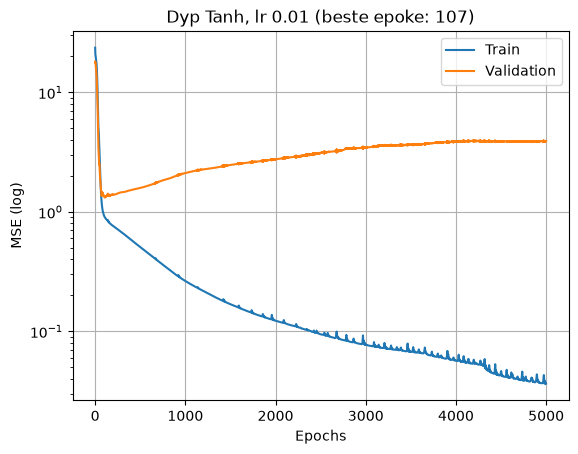

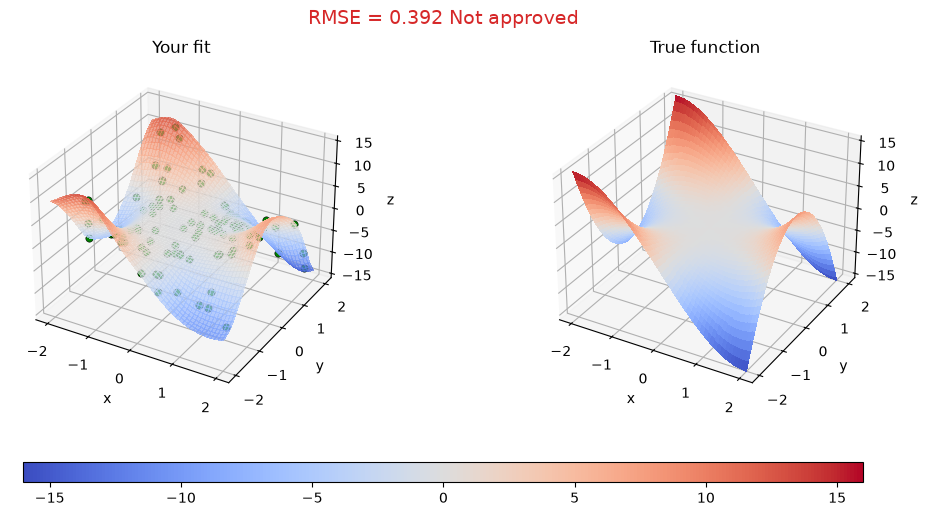

In [15]:

# Eksperiment 2: dyp Tanh, lr 0.01, med early stopping
model_tanh, best_tanh = run_with_early_stopping(
    "Dyp Tanh, lr 0.01", create_deep_model, nn.Tanh, 64, 0.01, y_tr_reg, y_val_reg)

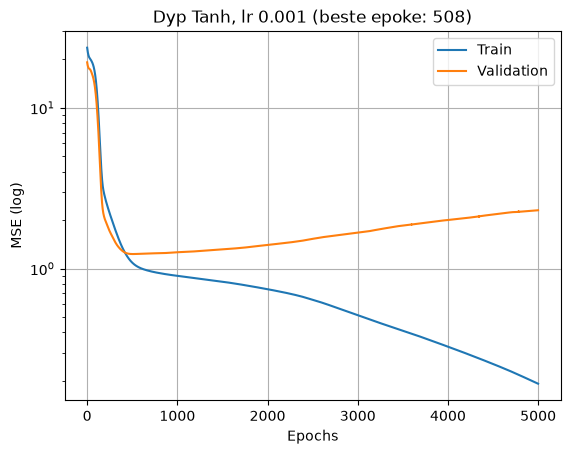

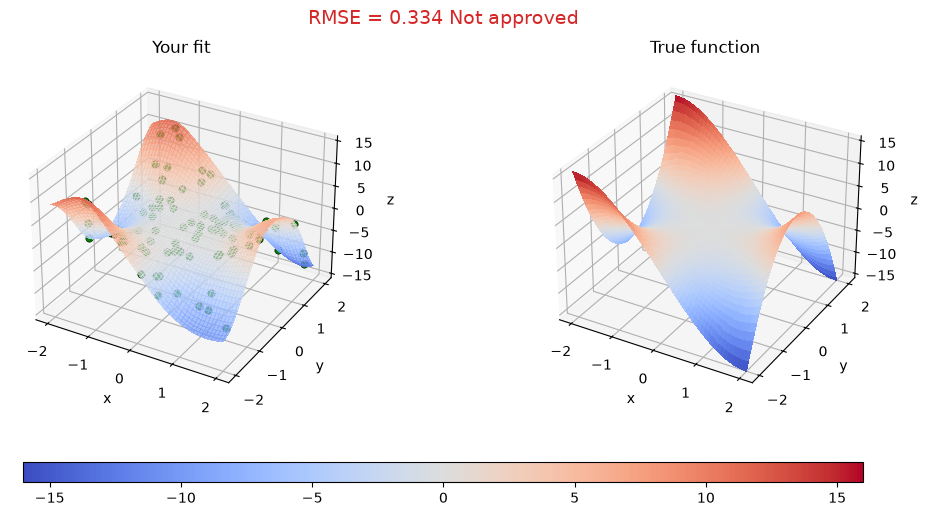

In [16]:
# Eksperiment 3: dyp Tanh, lr 0.001, med early stopping

model_tanh_slow, best_tanh_slow = run_with_early_stopping(
    "Dyp Tanh, lr 0.001", create_deep_model, nn.Tanh, 64, 0.001, y_tr_reg, y_val_reg)

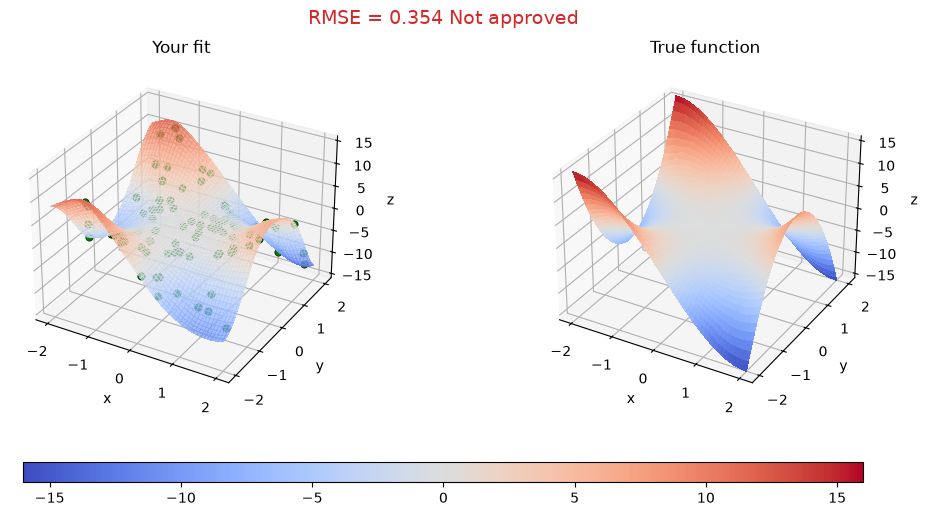

In [17]:
# Eksperiment 4: samme som eksperiment 3, men trent på alle treningsdata

model_tanh_all = create_deep_model(activation=nn.Tanh, hidden_size=64)
train_reg(model_tanh_all, x_train_reg, y_train_reg, x_val_reg, y_val_reg,
          loss_fn_reg, 0.001, best_tanh_slow + 1)
plot_test_fit(model_tanh_all)

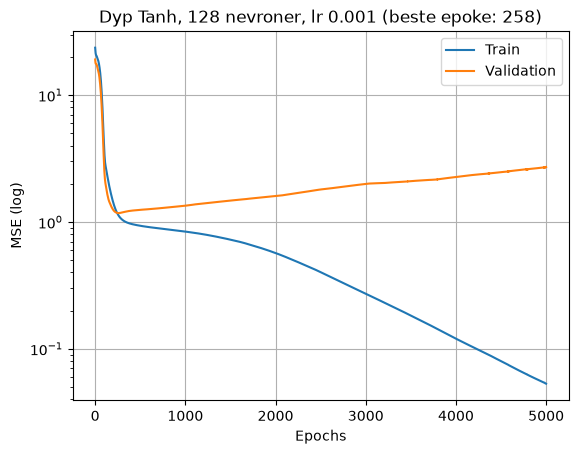

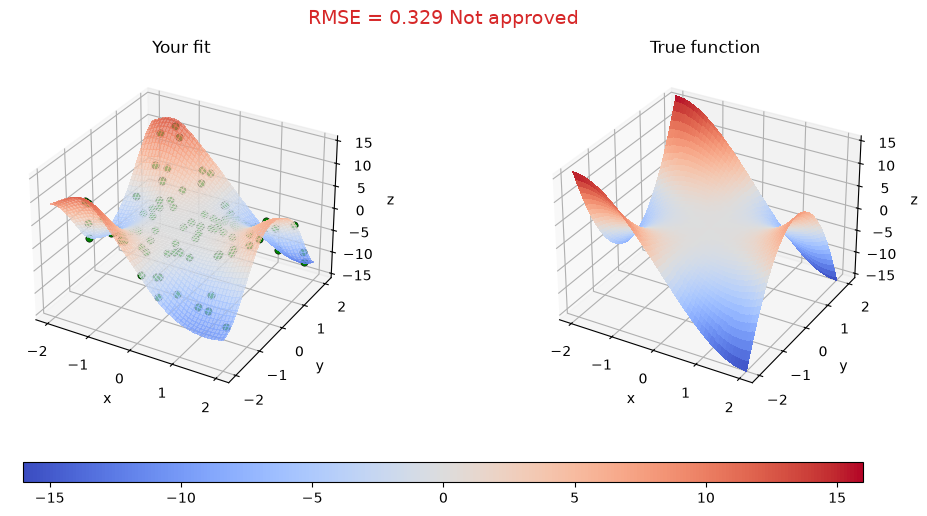

In [18]:
# Eksperiment 5: dyp Tanh, 128 nevroner, lr 0.001, med early stopping
model_tanh_128, best_tanh_128 = run_with_early_stopping(
    "Dyp Tanh, 128 nevroner, lr 0.001", create_deep_model, nn.Tanh, 128, 0.001, y_tr_reg, y_val_reg)

In [19]:
# Skalering av y: trekk fra snitt og del på standardavvik (fra treningsdelen)
y_mean = y_tr_reg.mean()
y_std = y_tr_reg.std()

y_tr_scaled = (y_tr_reg - y_mean) / y_std
y_val_scaled = (y_val_reg - y_mean) / y_std

print(f"Snitt: {y_mean:.3f}, std: {y_std:.3f}")
print(f"Skalert y fra {y_tr_scaled.min():.2f} til {y_tr_scaled.max():.2f}")

Snitt: 0.060, std: 4.870
Skalert y fra -3.17 til 3.20


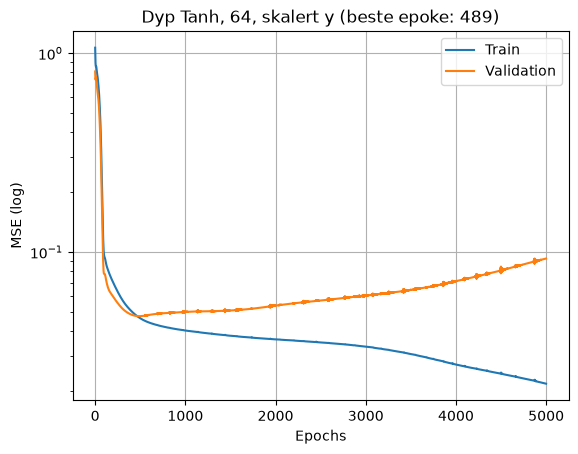

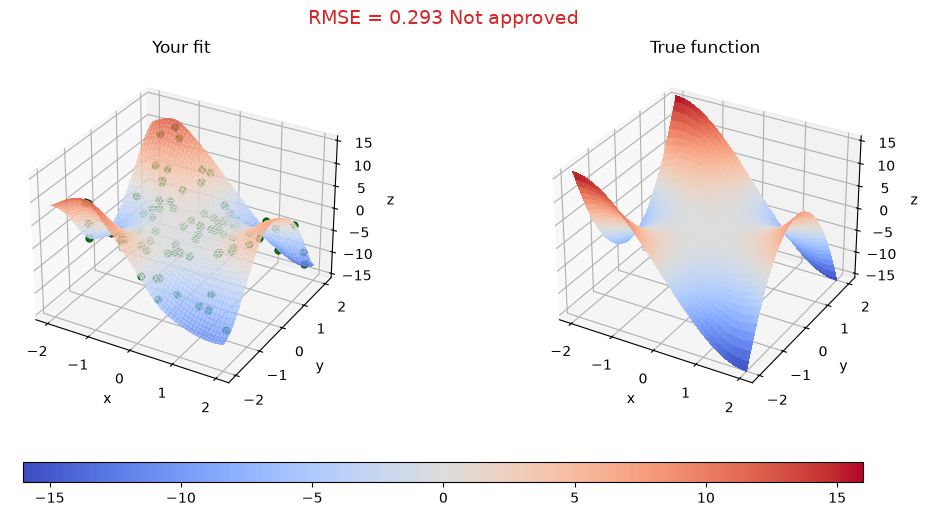

In [20]:
# Eksperiment 6: dyp Tanh, 64 nevroner, lr 0.001, skalert y
model_scaled, best_scaled = run_with_early_stopping(
    "Dyp Tanh, 64, skalert y", create_deep_model, nn.Tanh, 64, 0.001,
    y_tr_scaled, y_val_scaled, y_mean=y_mean, y_std=y_std)

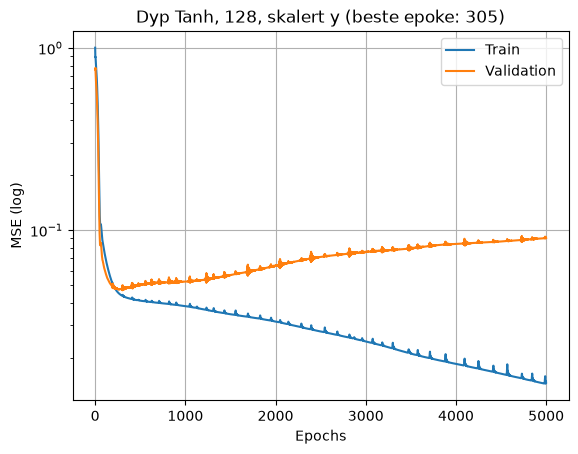

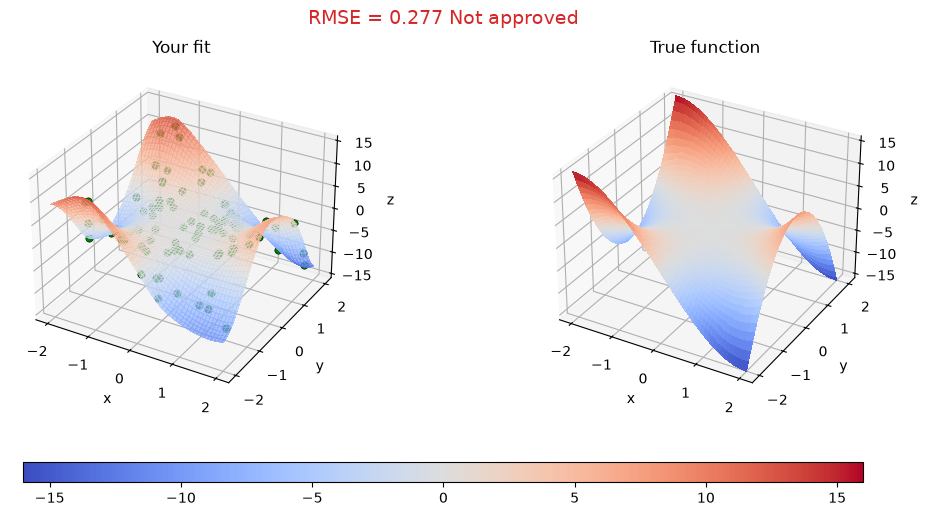

In [21]:
# Eksperiment 7: dyp Tanh, 128 nevroner, lr 0.001, skalert y
model_scaled_128, best_scaled_128 = run_with_early_stopping(
    "Dyp Tanh, 128, skalert y", create_deep_model, nn.Tanh, 128, 0.001,
    y_tr_scaled, y_val_scaled, y_mean=y_mean, y_std=y_std)

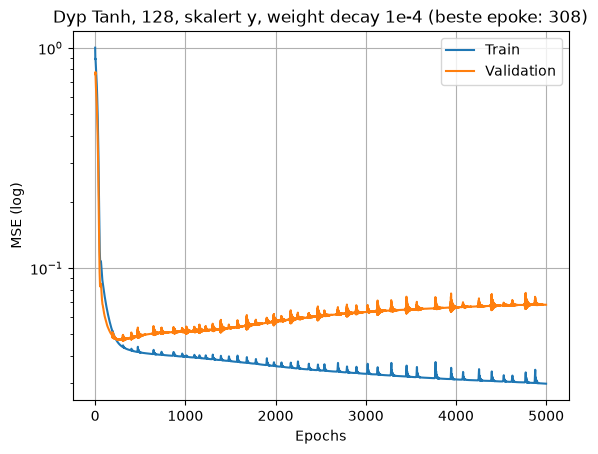

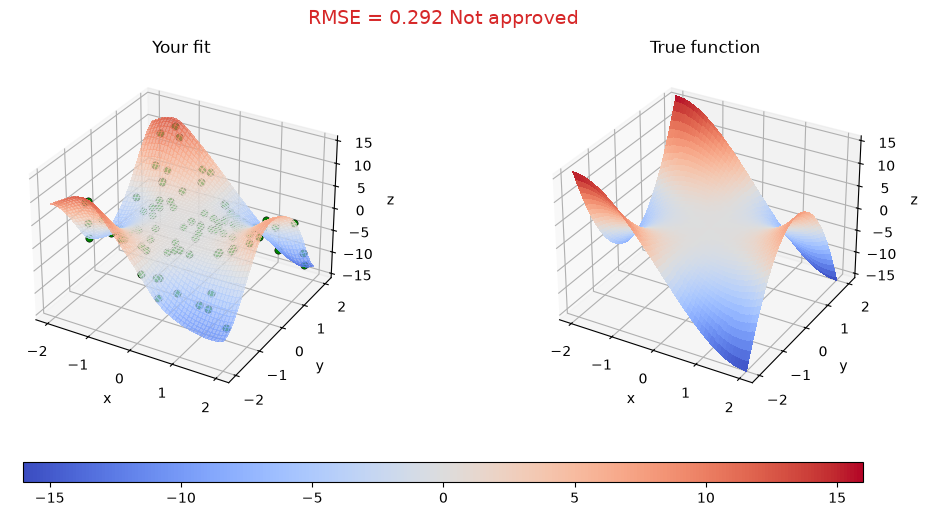

In [22]:
# Eksperiment 8: som eksperiment 7, med weight decay 1e-4
model_wd, best_wd = run_with_early_stopping(
    "Dyp Tanh, 128, skalert y, weight decay 1e-4", create_deep_model, nn.Tanh, 128, 0.001,
    y_tr_scaled, y_val_scaled, weight_decay=1e-4, y_mean=y_mean, y_std=y_std)

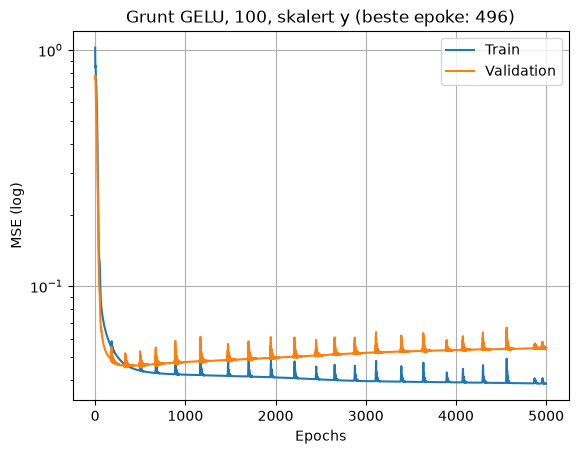

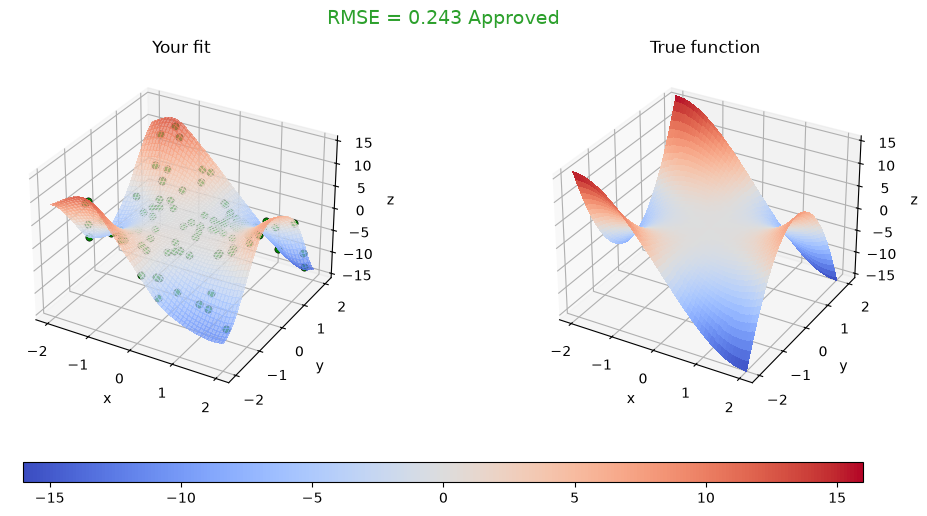

In [23]:
# Eksperiment 9: grunt nett (ett skjult lag), GELU, 100 nevroner, lr 0.01, skalert y
model_gelu, best_gelu = run_with_early_stopping(
    "Grunt GELU, 100, skalert y", create_model, nn.GELU, 100, 0.01,
    y_tr_scaled, y_val_scaled, y_mean=y_mean, y_std=y_std)

### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?


### ❓ Which optimization techniques did you try? What worked and what did not?


### ❓ How did you ensure reproducibility?

# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [24]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

C:\Users\joste\AppData\Local\Temp\ipykernel_3008\3436741196.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data = data.reset_index(names="ID")


,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [25]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


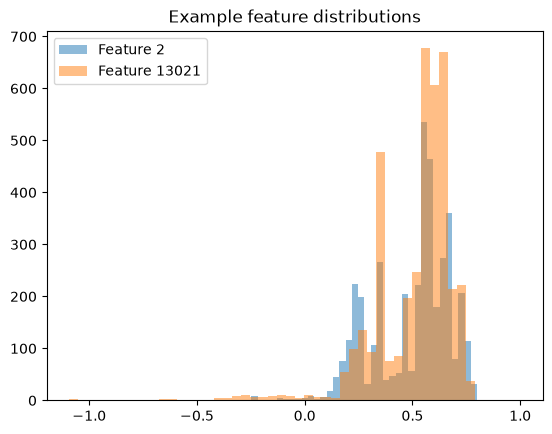

In [26]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

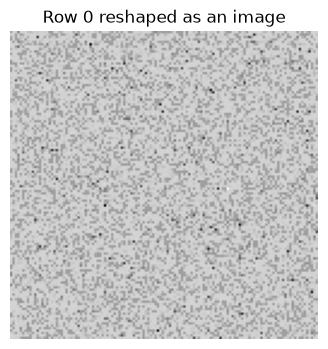

In [27]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [28]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


## 1. Finn riktig rekefølge

In [29]:
header = pd.read_csv("unsupervised_data.csv", nrows=0)
order = header.columns.str.replace("col_", "").astype(int).to_numpy()

print("Antall:", len(order))
print("Min og maks:", order.min(), order.max())
print("Antall unike:", len(np.unique(order)))

features = data.drop(columns="ID")
images = features.iloc[:, np.argsort(order)].to_numpy()
print("images:", images.shape)

Antall: 16384
Min og maks: 0 16383
Antall unike: 16384
images: (4000, 16384)


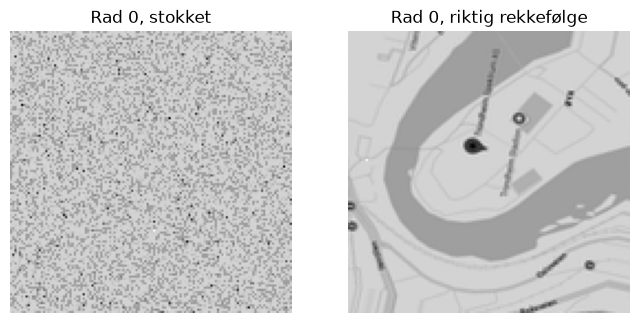

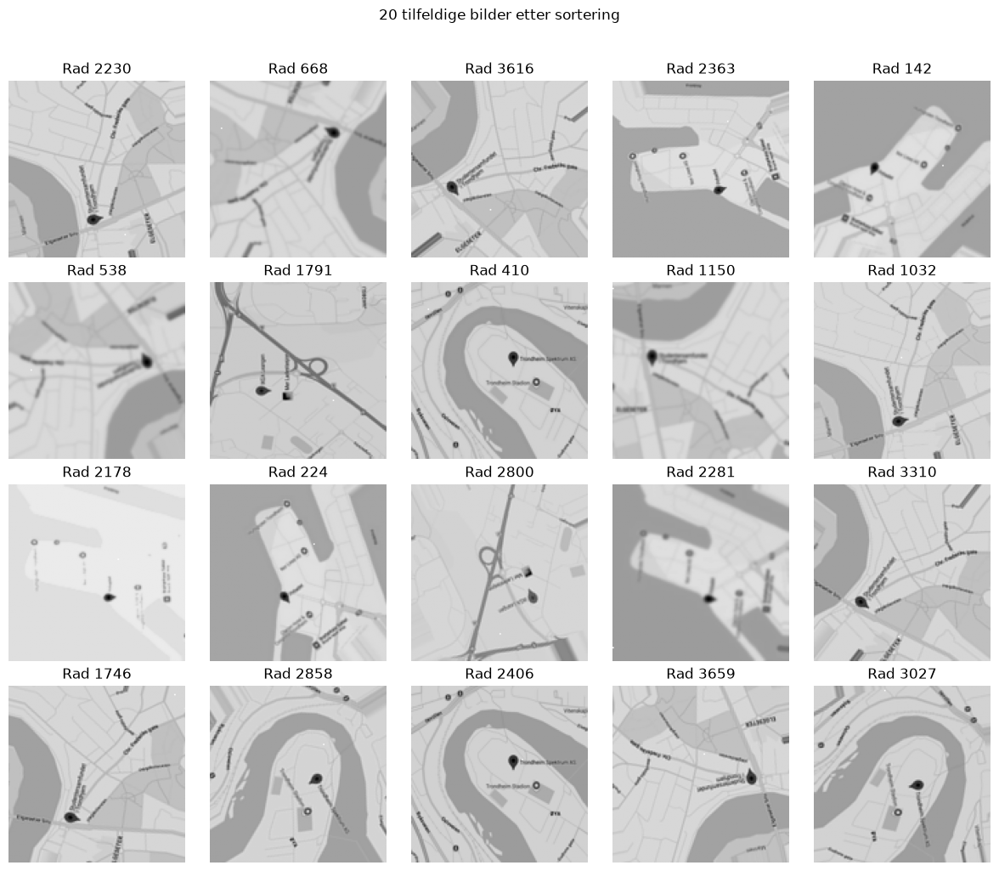

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(features.iloc[0].to_numpy().reshape(128, 128), cmap="gray")
axes[0].set_title("Rad 0, stokket")
axes[1].imshow(images[0].reshape(128, 128), cmap="gray")
axes[1].set_title("Rad 0, riktig rekkefølge")
for ax in axes:
    ax.axis("off")
plt.show()

np.random.seed(0)
idx = np.random.choice(len(images), 20, replace=False)
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for ax, i in zip(axes.flatten(), idx):
    ax.imshow(images[i].reshape(128, 128), cmap="gray")
    ax.set_title(f"Rad {i}")
    ax.axis("off")
fig.suptitle("20 tilfeldige bilder etter sortering", y=1.02)
plt.tight_layout()
plt.show()

## 2. Dimensjonsreduksjon

images_pca: (4000, 50)


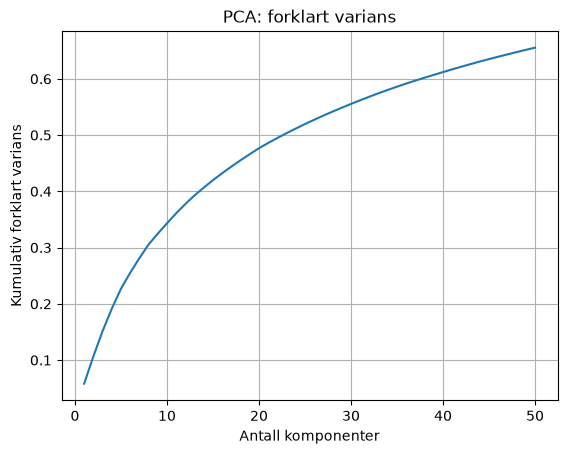

In [31]:
pca = PCA(n_components=50, random_state=42)
images_pca = pca.fit_transform(images)
print("images_pca:", images_pca.shape)

variance_sum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, 51), variance_sum)
plt.xlabel("Antall komponenter")
plt.ylabel("Kumulativ forklart varians")
plt.title("PCA: forklart varians")
plt.grid()
plt.show()

# Rekonstruksjonsfeil per bilde (brukes til anomalideteksjon i oppgave 4)
reconstructed = pca.inverse_transform(images_pca)
recon_error = np.mean((reconstructed - images) ** 2, axis=1)
anomalies = np.argsort(recon_error)[-3:]

In [32]:
tsne = TSNE(random_state=42, perplexity=30)
tsne_coords = tsne.fit_transform(images_pca)

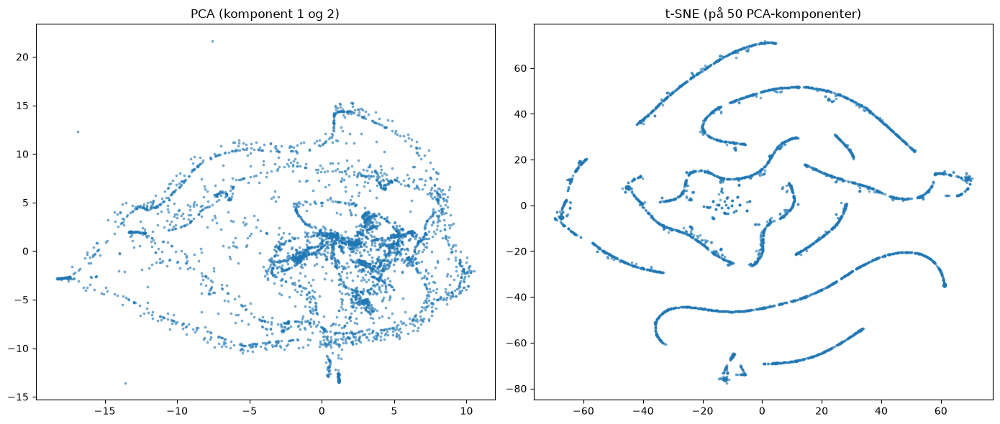

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(images_pca[:, 0], images_pca[:, 1], s=3, alpha=0.5)
axes[0].set_title("PCA (komponent 1 og 2)")
axes[1].scatter(tsne_coords[:, 0], tsne_coords[:, 1], s=3, alpha=0.5)
axes[1].set_title("t-SNE (på 50 PCA-komponenter)")
plt.tight_layout()
plt.show()

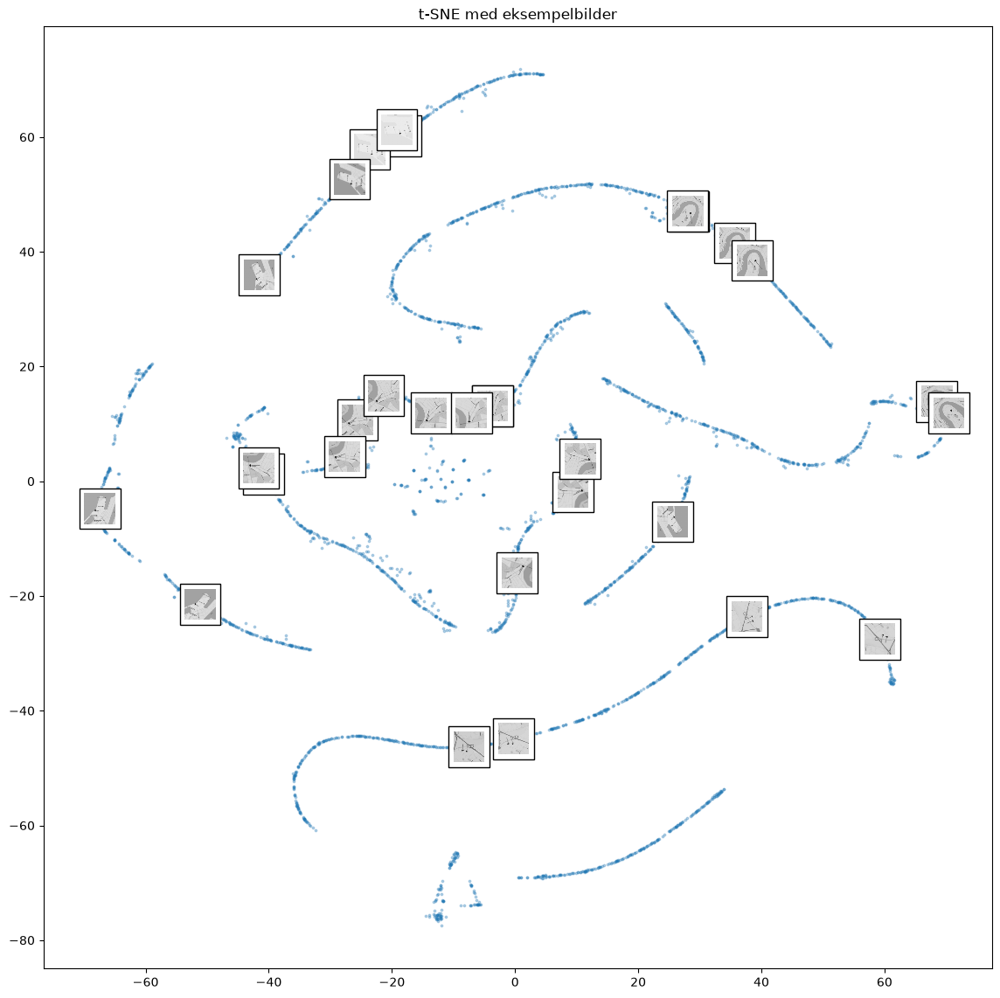

In [34]:
np.random.seed(0)
idx = np.random.choice(len(images), 30, replace=False)

fig, ax = plt.subplots(figsize=(14, 14))
ax.scatter(tsne_coords[:, 0], tsne_coords[:, 1], s=3, alpha=0.3)
for i in idx:
    thumb = OffsetImage(images[i].reshape(128, 128), zoom=0.2, cmap="gray")
    ax.add_artist(AnnotationBbox(thumb, tsne_coords[i], frameon=True))
ax.set_title("t-SNE med eksempelbilder")
plt.show()

## 3. Første forsøk: KMeans

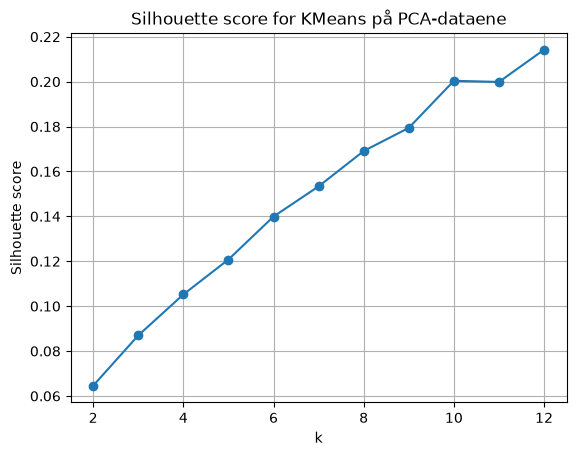

In [35]:
scores = []
k_values = range(2, 13)
for k in k_values:
    km_labels = KMeans(n_clusters=k, random_state=42).fit_predict(images_pca)
    scores.append(silhouette_score(images_pca, km_labels))

plt.plot(k_values, scores, marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette score for KMeans på PCA-dataene")
plt.grid()
plt.show()

(array([0, 1, 2, 3, 4], dtype=int32), array([ 646, 1083,  813,  878,  580]))


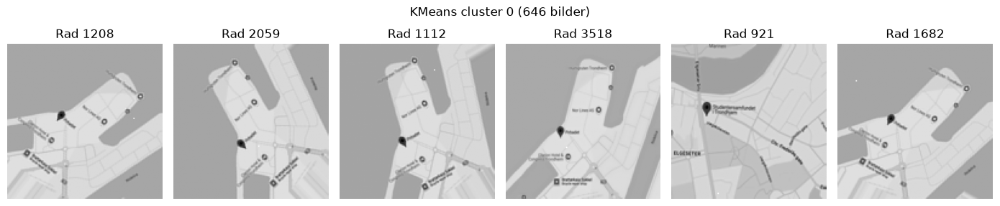

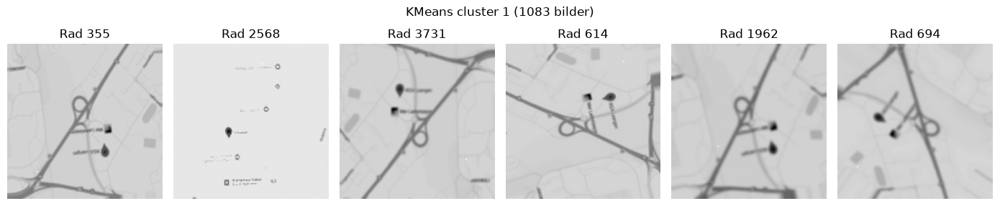

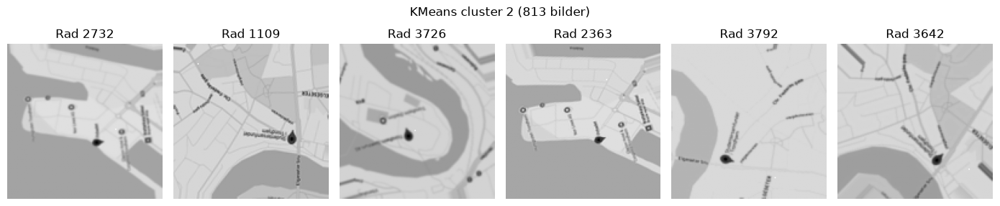

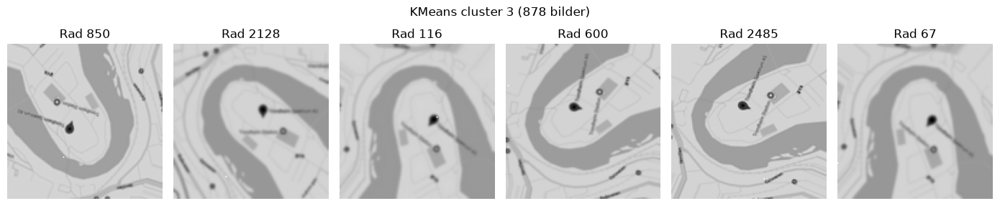

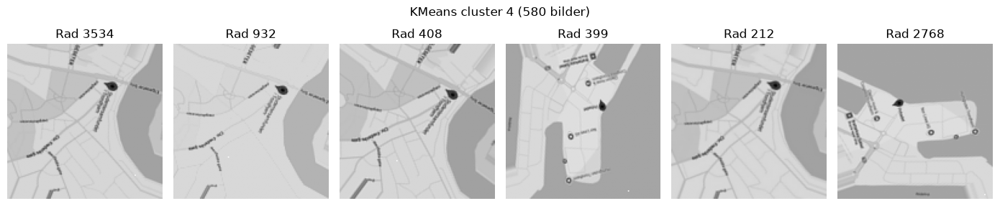

In [36]:
kmeans_labels = KMeans(n_clusters=5, random_state=42).fit_predict(images_pca)
print(np.unique(kmeans_labels, return_counts=True))

np.random.seed(0)
for c in range(5):
    rows = np.where(kmeans_labels == c)[0]
    pick = np.random.choice(rows, 6, replace=False)
    fig, axes = plt.subplots(1, 6, figsize=(14, 3))
    for ax, i in zip(axes, pick):
        ax.imshow(images[i].reshape(128, 128), cmap="gray")
        ax.set_title(f"Rad {i}")
        ax.axis("off")
    fig.suptitle(f"KMeans cluster {c} ({len(rows)} bilder)")
    plt.tight_layout()
    plt.show()

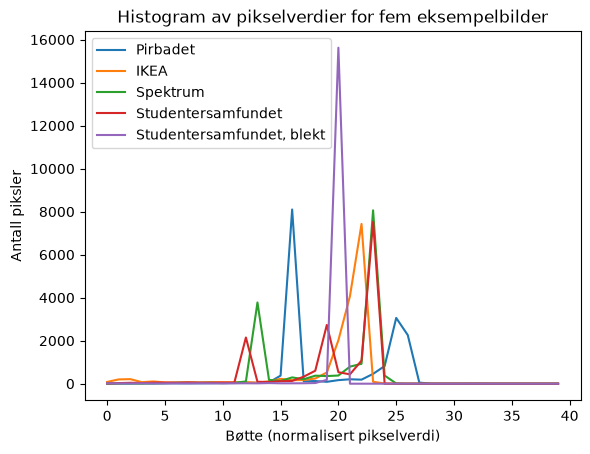

In [37]:
# Normaliser hvert bilde for seg, så bleke og normale bilder får samme kontrast
images_mean = images.mean(axis=1, keepdims=True)
images_std = images.std(axis=1, keepdims=True)
images_norm = (images - images_mean) / images_std

# Histogram per bilde: rotasjon og speilvending endrer ikke fargefordelingen
edges = np.linspace(-4, 4, 41)
histograms = np.array([np.histogram(img, bins=edges)[0] for img in images_norm])

for row, name in [(556, "Pirbadet"), (75, "IKEA"), (1211, "Spektrum"),
                  (1498, "Studentersamfundet"), (3899, "Studentersamfundet, blekt")]:
    plt.plot(histograms[row], label=name)
plt.xlabel("Bøtte (normalisert pikselverdi)")
plt.ylabel("Antall piksler")
plt.title("Histogram av pikselverdier for fem eksempelbilder")
plt.legend()
plt.show()

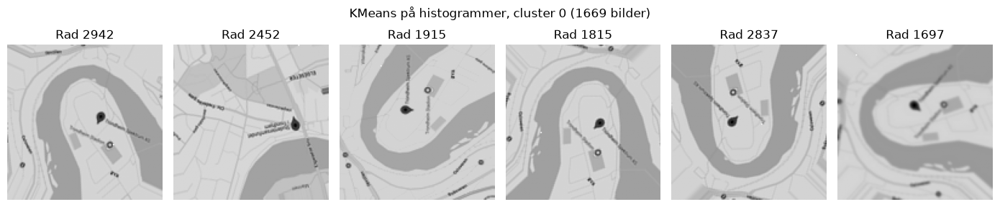

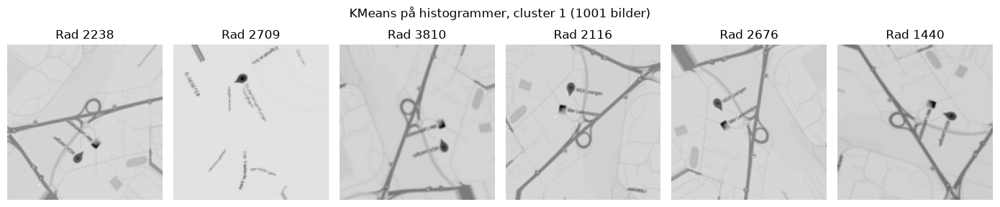

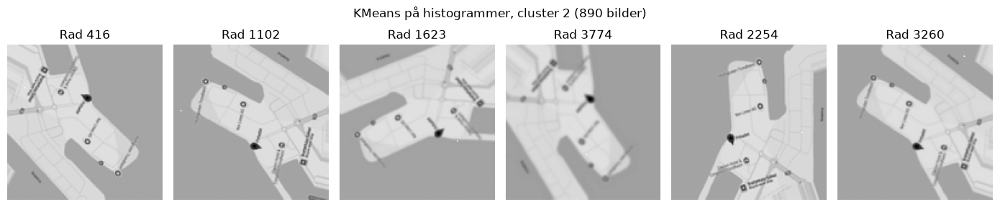

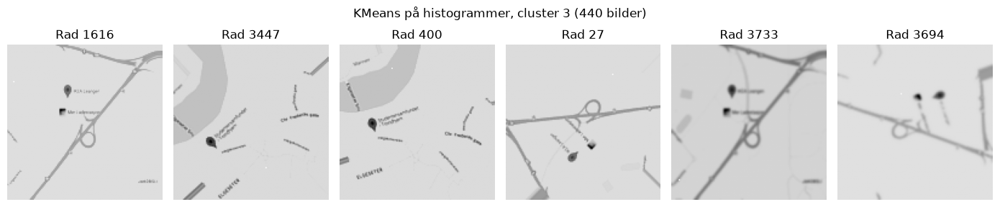

In [38]:
hist_labels = KMeans(n_clusters=4, random_state=42).fit_predict(histograms)

np.random.seed(0)
for c in range(4):
    rows = np.where(hist_labels == c)[0]
    pick = np.random.choice(rows, 6, replace=False)
    fig, axes = plt.subplots(1, 6, figsize=(14, 3))
    for ax, i in zip(axes, pick):
        ax.imshow(images[i].reshape(128, 128), cmap="gray")
        ax.set_title(f"Rad {i}")
        ax.axis("off")
    fig.suptitle(f"KMeans på histogrammer, cluster {c} ({len(rows)} bilder)")
    plt.tight_layout()
    plt.show()

## 4. DBSCAN på t-SNE

In [39]:
dbscan_labels = DBSCAN(eps=3, min_samples=10).fit_predict(tsne_coords)
print(np.unique(dbscan_labels, return_counts=True))

(array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17]), array([ 19, 269, 671, 176, 379, 123,  67, 210, 338, 164, 338, 263,  78,
       116, 413,  89, 178,  29,  80]))


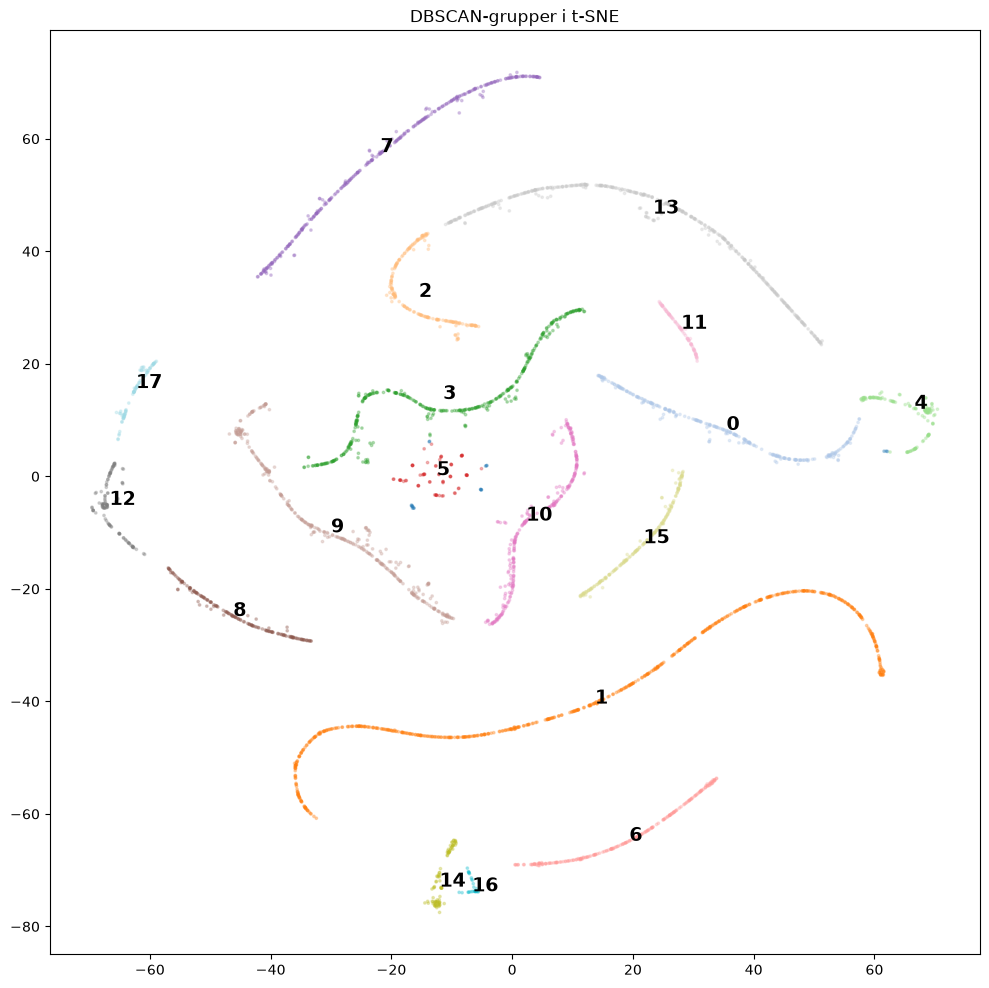

In [40]:
plt.figure(figsize=(12, 12))
plt.scatter(tsne_coords[:, 0], tsne_coords[:, 1], s=3, alpha=0.3, c=dbscan_labels, cmap="tab20")

for g in np.unique(dbscan_labels):
    if g == -1:
        continue
    rows = np.where(dbscan_labels == g)[0]
    plt.text(np.median(tsne_coords[rows, 0]), np.median(tsne_coords[rows, 1]),
             str(g), fontsize=14, weight="bold")

plt.title("DBSCAN-grupper i t-SNE")
plt.show()

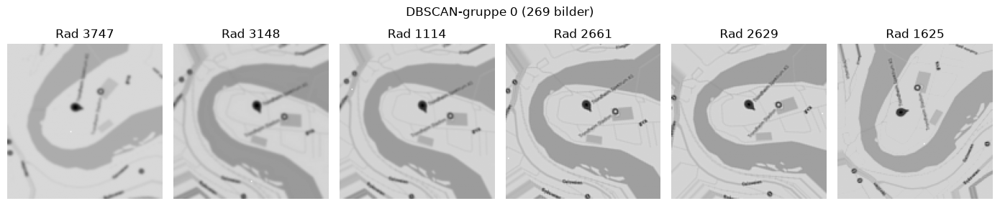

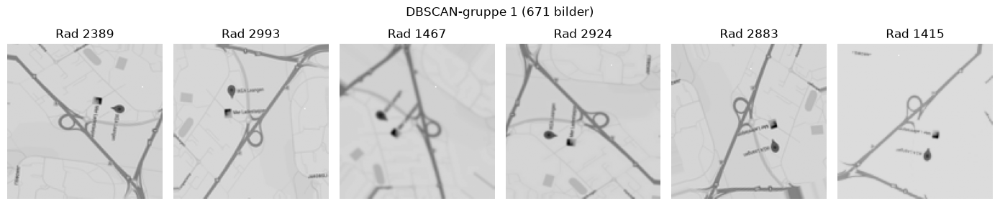

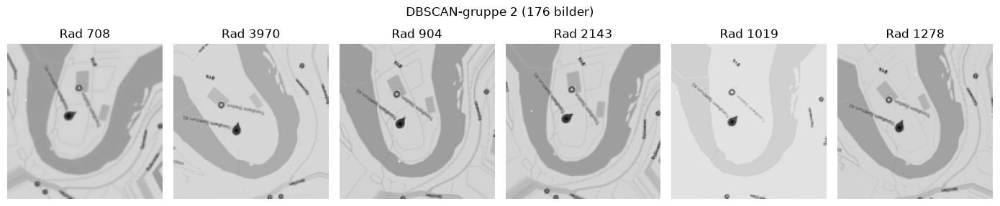

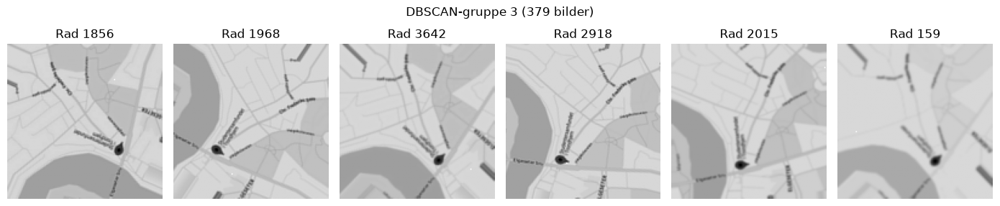

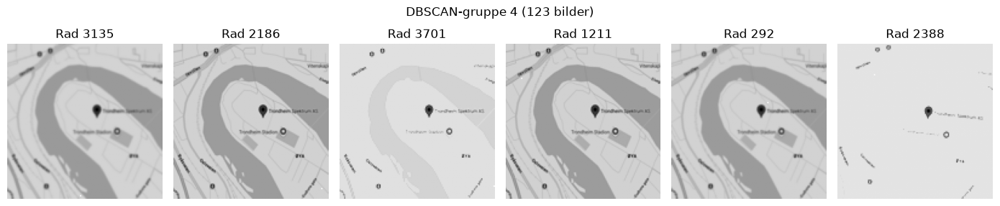

...

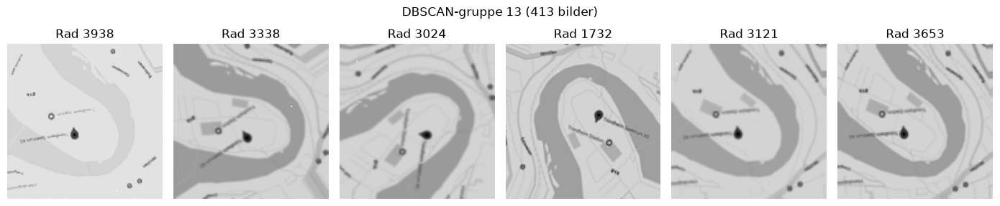

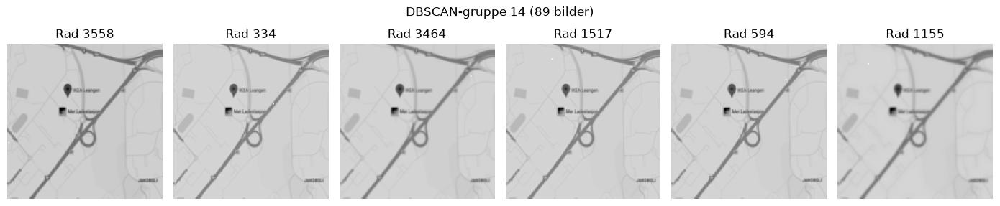

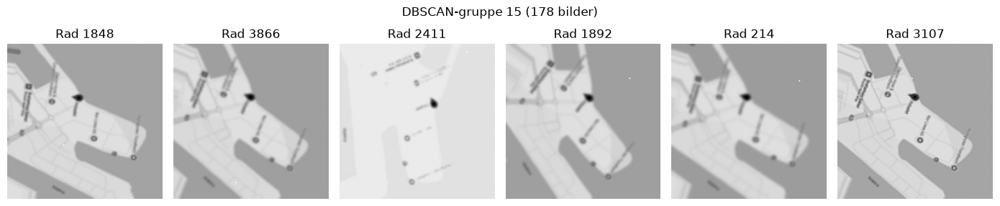

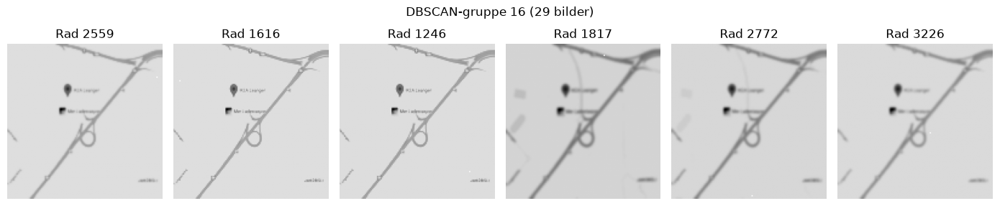

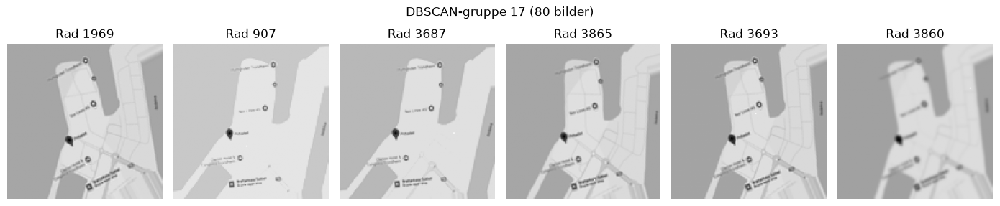

In [41]:
np.random.seed(0)
for g in np.unique(dbscan_labels):
    if g == -1:
        continue
    rows = np.where(dbscan_labels == g)[0]
    pick = np.random.choice(rows, 6, replace=False)
    fig, axes = plt.subplots(1, 6, figsize=(14, 3))
    for ax, i in zip(axes, pick):
        ax.imshow(images[i].reshape(128, 128), cmap="gray")
        ax.set_title(f"Rad {i}")
        ax.axis("off")
    fig.suptitle(f"DBSCAN-gruppe {g} ({len(rows)} bilder)")
    plt.tight_layout()
    plt.show()

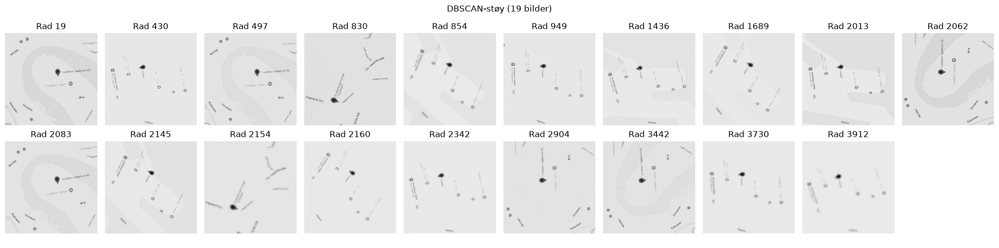

In [42]:
noise_rows = np.where(dbscan_labels == -1)[0]

fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for ax in axes.flatten():
    ax.axis("off")
for ax, i in zip(axes.flatten(), noise_rows):
    ax.imshow(images[i].reshape(128, 128), cmap="gray")
    ax.set_title(f"Rad {i}")
fig.suptitle(f"DBSCAN-støy ({len(noise_rows)} bilder)")
plt.tight_layout()
plt.show()

## 5. Fra DBSCAN-grupper til steder

In [43]:
place_names = ["Pirbadet", "IKEA", "Spektrum", "Samfundet"]

group_to_place = {
    7: 0, 8: 0, 11: 0, 12: 0, 15: 0, 17: 0,   # Pirbadet
    1: 1, 6: 1, 14: 1, 16: 1,                  # IKEA
    0: 2, 2: 2, 4: 2, 13: 2,                   # Spektrum
    3: 3, 9: 3, 10: 3,                         # Samfundet
}

place_labels = np.array([group_to_place.get(g, -1) for g in dbscan_labels])
print(np.unique(place_labels, return_counts=True))

(array([-1,  0,  1,  2,  3]), array([ 86, 954, 999, 981, 980]))


In [44]:
known = place_labels != -1
unknown = place_labels == -1

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(images_pca[known], place_labels[known])

final_labels = place_labels.copy()
final_labels[unknown] = knn.predict(images_pca[unknown])
print(np.unique(final_labels, return_counts=True))

(array([0, 1, 2, 3]), array([ 974,  999,  998, 1029]))


In [45]:
submission = pd.DataFrame({"ID": data["ID"], "cluster": final_labels})
submission.to_csv("submission.csv", index=False)
submission.head()

,ID,cluster
0,0,2
1,1,1
2,2,2
3,3,1
4,4,3


## Oppgave 3: Visualisering og identifisering

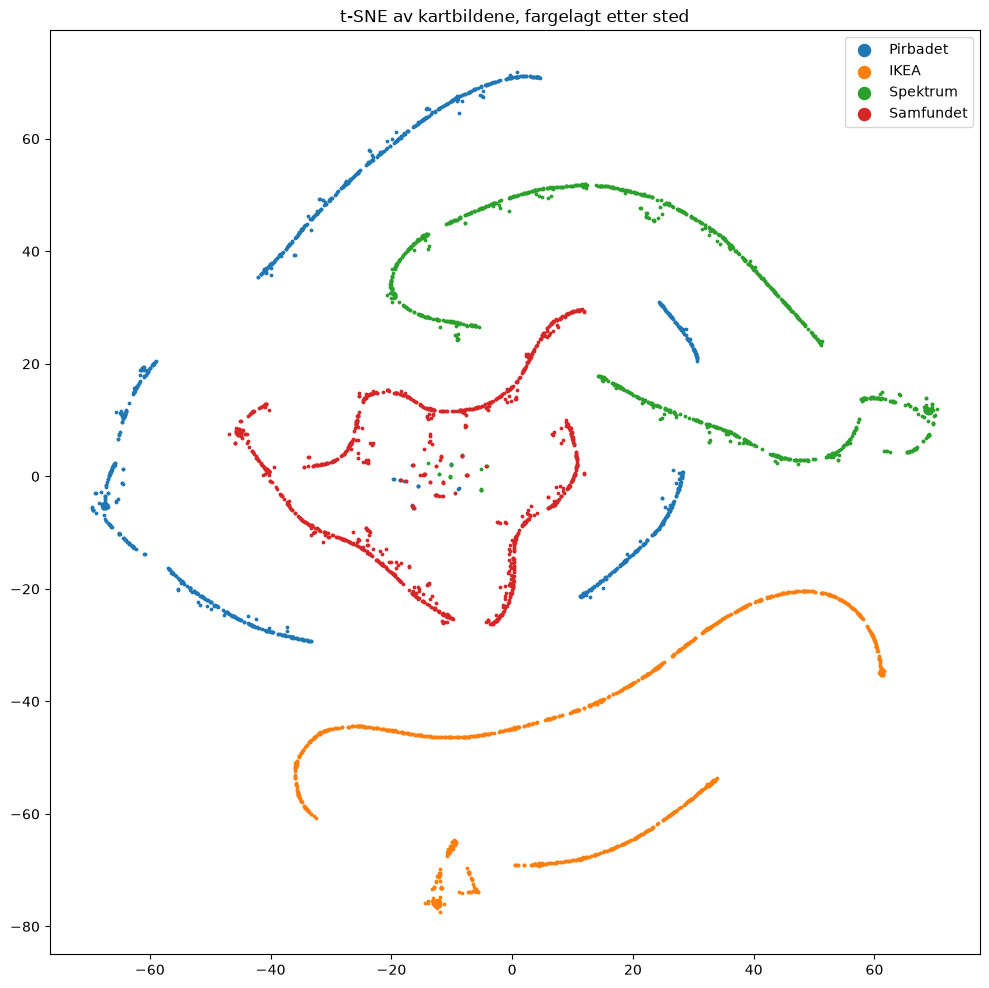

In [46]:
plt.figure(figsize=(12, 12))
for p in range(4):
    mask = final_labels == p
    plt.scatter(tsne_coords[mask, 0], tsne_coords[mask, 1], s=3, label=place_names[p])
plt.title("t-SNE av kartbildene, fargelagt etter sted")
plt.legend(markerscale=5)
plt.show()

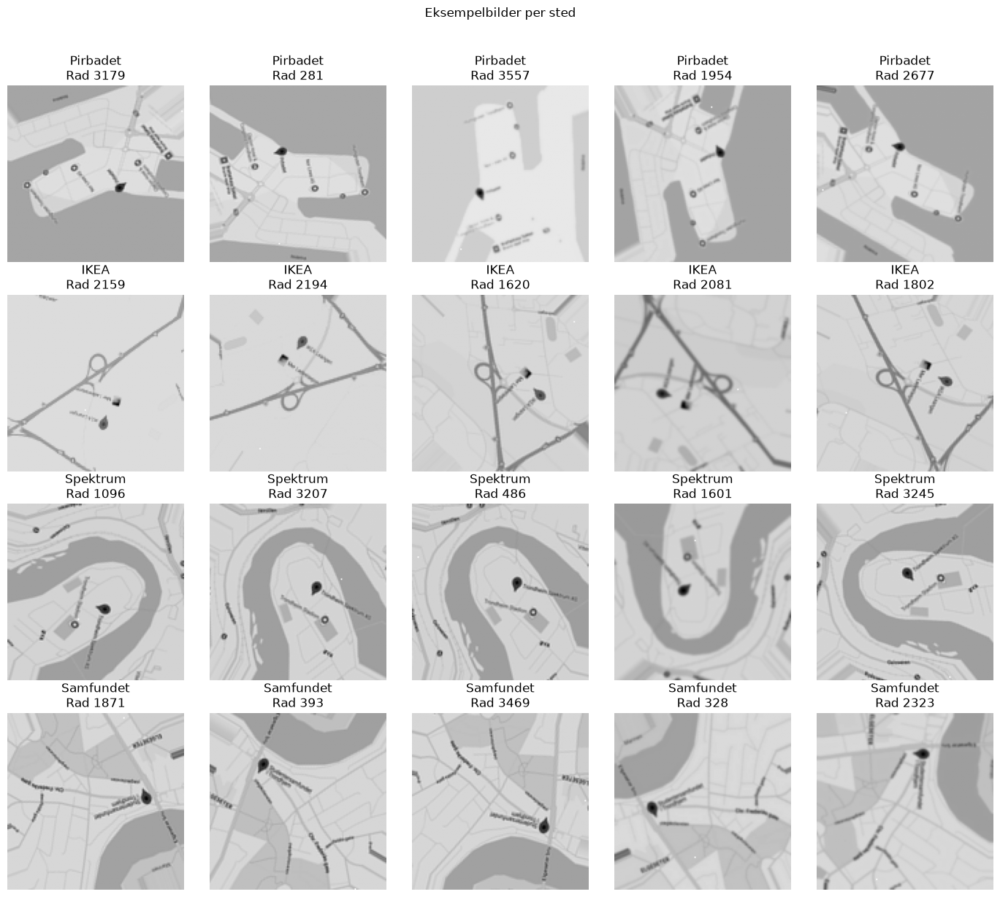

In [47]:
np.random.seed(42)
not_anomaly = ~np.isin(np.arange(len(images)), anomalies)

fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for p in range(4):
    rows = np.where((final_labels == p) & not_anomaly)[0]
    pick = np.random.choice(rows, 5, replace=False)
    for ax, i in zip(axes[p], pick):
        ax.imshow(images[i].reshape(128, 128), cmap="gray")
        ax.set_title(f"{place_names[p]}\nRad {i}")
        ax.axis("off")
fig.suptitle("Eksempelbilder per sted", y=1.02)
plt.tight_layout()
plt.show()

## Oppgave 4: Anomalier

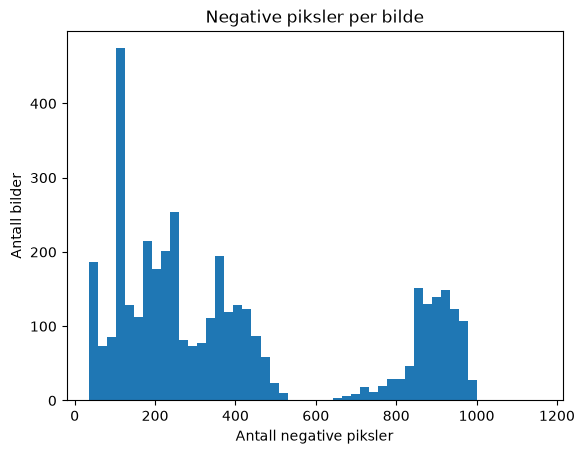

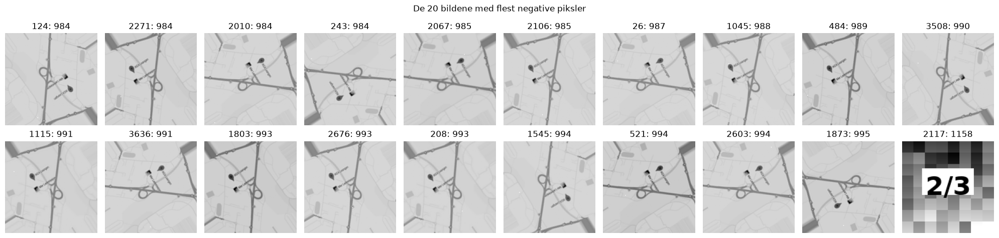

In [48]:
neg_count = (images < 0).sum(axis=1)

plt.hist(neg_count, bins=50)
plt.xlabel("Antall negative piksler")
plt.ylabel("Antall bilder")
plt.title("Negative piksler per bilde")
plt.show()

top20 = np.argsort(neg_count)[-20:]
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for ax, i in zip(axes.flatten(), top20):
    ax.imshow(images[i].reshape(128, 128), cmap="gray")
    ax.set_title(f"{i}: {neg_count[i]}")
    ax.axis("off")
fig.suptitle("De 20 bildene med flest negative piksler")
plt.tight_layout()
plt.show()

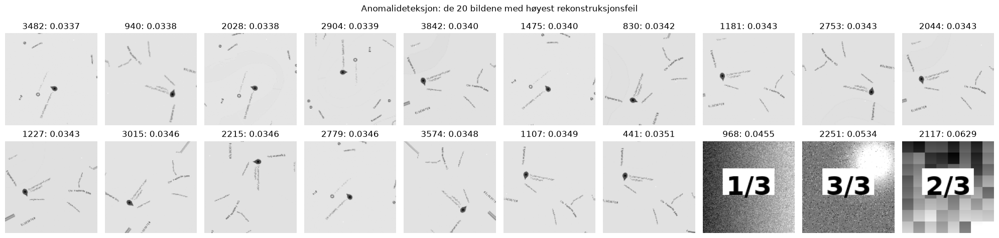

In [49]:
top20 = np.argsort(recon_error)[-20:]
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for ax, i in zip(axes.flatten(), top20):
    ax.imshow(images[i].reshape(128, 128), cmap="gray")
    ax.set_title(f"{i}: {recon_error[i]:.4f}")
    ax.axis("off")
fig.suptitle("Anomalideteksjon: de 20 bildene med høyest rekonstruksjonsfeil")
plt.tight_layout()
plt.show()

Anomalier: [ 968 2117 2251]


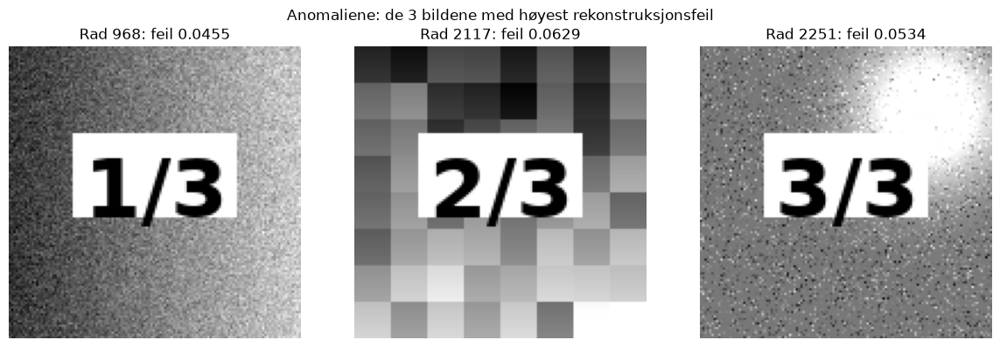

In [50]:
print("Anomalier:", np.sort(anomalies))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, i in zip(axes, np.sort(anomalies)):
    ax.imshow(images[i].reshape(128, 128), cmap="gray")
    ax.set_title(f"Rad {i}: feil {recon_error[i]:.4f}")
    ax.axis("off")
fig.suptitle("Anomaliene: de 3 bildene med høyest rekonstruksjonsfeil")
plt.tight_layout()
plt.show()

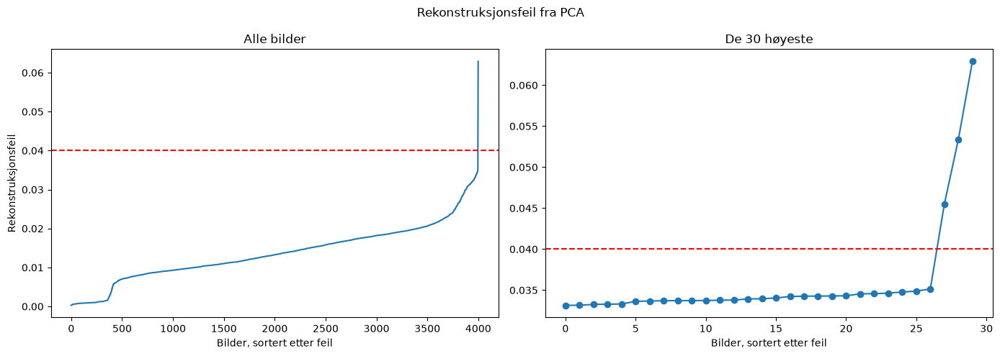

In [51]:
sorted_err = np.sort(recon_error)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(sorted_err)
axes[0].axhline(0.04, linestyle="--", color="red")
axes[0].set_title("Alle bilder")
axes[0].set_xlabel("Bilder, sortert etter feil")
axes[0].set_ylabel("Rekonstruksjonsfeil")

axes[1].plot(sorted_err[-30:], marker="o")
axes[1].axhline(0.04, linestyle="--", color="red")
axes[1].set_title("De 30 høyeste")
axes[1].set_xlabel("Bilder, sortert etter feil")

fig.suptitle("Rekonstruksjonsfeil fra PCA")
plt.tight_layout()
plt.show()

### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.


### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.


### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?


### ❓ List the facilities in Trondheim and how you identified them.

### ❓ How did you detect the rows that do not belong, and what were they?


---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [52]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [53]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [54]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [55]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)